# E0 — 발전소 A+B 통합 Isolation Forest 단일 모델 학습

**목적:** 태양광 발전소 A/B의 공통 인버터 특징을 사용해 **단일 비지도 이상 탐지 모델**을 학습하고, 발전소별 이상 점수/경보를 분석합니다.

- Python **3.10.20** 호환; `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `joblib` 사용. **PyTorch는 E0의 Isolation Forest 구현에 필요하지 않습니다.**
- 입력: 직전 정제 노트북이 출력한 `06_common_train.csv`, `06_common_validation.csv`, `06_common_test.csv`
- 데이터 누수 방지: Train에서만 전처리 적합, Validation에서 임계값 설정, Test에서는 최종 적용
- **실제 이상/정상 레이블이 없으므로 경보율을 오탐률 또는 정확도로 해석하지 않습니다.**
- 최종 OPC UA의 10개 가상 발전소에 적용할 공통 모델 1개를 학습합니다. 신규 발전소 일반화 성능 검증은 별도 과제입니다.


## 0. 설정 및 라이브러리

In [1]:
from pathlib import Path
import json
import platform
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

DATA_DIR = Path('clean_output')
if not DATA_DIR.exists() and Path('/mnt/data/clean_output').exists():
    DATA_DIR = Path('/mnt/data/clean_output')
OUT_DIR = Path('e0_output')
OUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    'train': DATA_DIR / '06_common_train.csv',
    'validation': DATA_DIR / '06_common_validation.csv',
    'test': DATA_DIR / '06_common_test.csv',
}
FEATURES = ['rate_output', 'energy_ratio', 'power_ratio_diff', 'ratio_ma_60min']
SEED = 42
N_ESTIMATORS = 200
MAX_SAMPLES = 2048
VALIDATION_ALERT_QUANTILE = 0.98  # 상위 2% 경보 정책. 실제 오탐률이 아님.
BALANCE_PLANTS = True
print('Python:', sys.version.split()[0], 'sklearn:', sklearn.__version__)
for key, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f'{key}: {path.resolve()} 를 찾을 수 없습니다.')
print('Input directory:', DATA_DIR.resolve())


Python: 3.10.20 sklearn: 1.7.2
Input directory: D:\KKW\_Repository\VSCode\github\CBNU.Master.1yr.intelIoT\termproj\llm_suggest\clean_output


## 1. 입력 데이터 점검

In [2]:
sets = {}
required = {'source_plant', 'source_row', 'timestamp', 'split', *FEATURES}
for part, path in FILES.items():
    df = pd.read_csv(path, encoding='utf-8-sig', low_memory=False)
    missing_cols = sorted(required - set(df.columns))
    if missing_cols:
        raise ValueError(f'{part}: 필수 컬럼 누락: {missing_cols}')
    if not (df['split'].astype(str) == part).all():
        raise ValueError(f'{part}: split 컬럼이 파일명과 일치하지 않습니다.')
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')
    df['source_plant'] = df['source_plant'].astype(str)
    for f in FEATURES:
        df[f] = pd.to_numeric(df[f], errors='coerce')
    ok = np.isfinite(df[FEATURES].to_numpy(dtype=float)).all(axis=1)
    if not ok.all():
        raise ValueError(f'{part}: E0 특징에 결측/비유한 값 {int((~ok).sum()):,}개 행 존재. 정제 단계 확인 필요.')
    if df.duplicated(subset=['source_plant', 'source_row']).any():
        raise ValueError(f'{part}: source_plant + source_row 중복 존재')
    sets[part] = df

# 세 구간 간 동일 원본 행 겹침 검사
keys = {k: set(zip(v['source_plant'], v['source_row'])) for k,v in sets.items()}
for a, c in [('train','validation'), ('train','test'), ('validation','test')]:
    assert not (keys[a] & keys[c]), f'{a}/{c} 원본 행 중복 발견'

summary = pd.concat([
    df.groupby('source_plant').size().rename('rows').reset_index().assign(split=part)
    for part, df in sets.items()
], ignore_index=True)[['split','source_plant','rows']]
print(summary.to_string(index=False))
summary.to_csv(OUT_DIR / '01_input_summary.csv', index=False, encoding='utf-8-sig')


     split source_plant   rows
     train            A 121909
     train            B  56571
validation            A  26124
validation            B  12123
      test            A  26124
      test            B  12123


## 2. Train 학습 표본 구성

원본 A/B의 학습 행 수가 다르므로 기본값은 **발전소별 동일 수량**을 비복원 추출합니다. 시간 순서를 무작위로 섞어 *모델에 입력하는 순서*는 Isolation Forest에 영향이 없지만, 학습·평가 시간 분할 자체는 유지합니다. 출력 결과에는 원본 Train 행을 모두 보존합니다.

In [3]:
train = sets['train']
counts = train.groupby('source_plant').size()
if len(counts) != 2:
    raise ValueError(f'예상한 원본 발전소 2곳이 아닙니다: {counts.to_dict()}')
if BALANCE_PLANTS:
    n_each = int(counts.min())
    fit_df = pd.concat([
        g.sample(n=n_each, random_state=SEED).copy()
        for _,g in train.groupby('source_plant', sort=True)
    ], ignore_index=True)
else:
    fit_df = train.copy()
print('학습 표본 (실제 모델 fit):')
print(fit_df.groupby('source_plant').size().to_string())
print('총', len(fit_df), '건')


학습 표본 (실제 모델 fit):
source_plant
A    56571
B    56571
총 113142 건


## 3. 단일 Isolation Forest 학습

- **한 개**의 `Pipeline(RobustScaler, IsolationForest)`만 학습합니다.
- `source_plant`, 정격출력, 기상 컬럼 및 시각은 E0 학습 입력에서 제외합니다.
- 이상 점수는 `-score_samples()`로 계산하여 **높을수록 이상**으로 통일합니다.
- 경보 임계값은 Validation 점수의 98백분위수로 설정하며, 이는 실험용 경보량 정책입니다.

In [4]:
model = Pipeline([
    ('scale', RobustScaler()),
    ('iforest', IsolationForest(
        n_estimators=N_ESTIMATORS,
        max_samples=MAX_SAMPLES,
        contamination='auto',
        random_state=SEED,
        n_jobs=-1,
    )),
])
model.fit(fit_df[FEATURES].to_numpy(dtype=float))

scored = {}
for part, df in sets.items():
    res = df.copy()
    x = res[FEATURES].to_numpy(dtype=float)
    res['anomaly_score'] = -model.score_samples(x)
    scored[part] = res

threshold = float(scored['validation']['anomaly_score'].quantile(VALIDATION_ALERT_QUANTILE))
print('Validation 경보 임계값:', round(threshold, 6))
for part, df in scored.items():
    df['is_alert'] = df['anomaly_score'] >= threshold
    df['threshold'] = threshold
    df.to_csv(OUT_DIR / f'02_{part}_scored.csv', index=False, encoding='utf-8-sig')

joblib.dump(model, OUT_DIR / 'e0_unified_iforest.joblib')
meta = {
    'model': 'IsolationForest', 'experiment': 'E0',
    'features_ordered': FEATURES, 'anomaly_score_definition': '-score_samples; larger = more anomalous',
    'decision_rule': 'anomaly_score >= threshold', 'threshold': threshold,
    'threshold_source': 'validation quantile', 'threshold_quantile': VALIDATION_ALERT_QUANTILE,
    'validation_alert_rate_is_not_false_positive_rate': True,
    'balance_plants': BALANCE_PLANTS, 'fit_counts': fit_df.groupby('source_plant').size().to_dict(),
    'seed': SEED, 'n_estimators': N_ESTIMATORS, 'max_samples': MAX_SAMPLES,
    'python_version': platform.python_version(), 'sklearn_version': sklearn.__version__,
    'notes': 'Unlabeled data; alarms are anomaly candidates, not diagnosed failures.',
}
(OUT_DIR / 'e0_metadata.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')


Validation 경보 임계값: 0.608134


745

## 4. 발전소별 점수·경보 요약

In [5]:
stats_rows=[]
for part, df in scored.items():
    for plant, g in df.groupby('source_plant'):
        s = g['anomaly_score']
        stats_rows.append({
            'split': part, 'plant': plant, 'rows': len(g),
            'alerts': int(g['is_alert'].sum()), 'alert_rate': float(g['is_alert'].mean()),
            'score_mean': float(s.mean()), 'score_median': float(s.median()),
            'score_p95': float(s.quantile(.95)), 'score_p99': float(s.quantile(.99)),
            'score_max': float(s.max()),
            'from': g['timestamp'].min(), 'to': g['timestamp'].max(),
        })
metrics=pd.DataFrame(stats_rows)
metrics.to_csv(OUT_DIR/'03_plant_score_summary.csv', index=False, encoding='utf-8-sig')
print(metrics[['split','plant','rows','alerts','alert_rate','score_median','score_p99']].to_string(index=False, formatters={'alert_rate': '{:.2%}'.format, 'score_median':'{:.4f}'.format, 'score_p99':'{:.4f}'.format}))
print('\n주의: alert_rate는 이상 후보 경보 비율이며 실제 오탐률이 아닙니다.')


     split plant   rows  alerts alert_rate score_median score_p99
     train     A 121909    2174      1.78%       0.4060    0.6357
     train     B  56571    1112      1.97%       0.4043    0.6326
validation     A  26124     498      1.91%       0.4031    0.6375
validation     B  12123     267      2.20%       0.4070    0.6304
      test     A  26124     632      2.42%       0.4097    0.6472
      test     B  12123     222      1.83%       0.4062    0.6240

주의: alert_rate는 이상 후보 경보 비율이며 실제 오탐률이 아닙니다.


## 5. Test 이상 사례 및 월별 추이

In [6]:
test = scored['test'].copy()
case_cols = ['source_plant','timestamp','source_row',*FEATURES,'anomaly_score','is_alert']
# 이상 점수가 큰 행 우선 확인: 고장 정답이라는 의미는 아님
cases = (test.sort_values(['source_plant','anomaly_score'], ascending=[True,False])
            .groupby('source_plant', group_keys=False).head(30))
cases[case_cols].to_csv(OUT_DIR/'04_test_top30_per_plant.csv', index=False, encoding='utf-8-sig')
print(cases[case_cols].groupby('source_plant').head(5).to_string(index=False))

test['year_month'] = test['timestamp'].dt.to_period('M').astype(str)
monthly = (test.groupby(['source_plant','year_month'], as_index=False)
           .agg(rows=('is_alert','size'), alerts=('is_alert','sum'),
                mean_score=('anomaly_score','mean')))
monthly['alert_rate']=monthly['alerts']/monthly['rows']
monthly.to_csv(OUT_DIR/'05_test_monthly_alerts.csv', index=False, encoding='utf-8-sig')


source_plant           timestamp  source_row  rate_output  energy_ratio  power_ratio_diff  ratio_ma_60min  anomaly_score  is_alert
           A 2026-05-22 12:10:00      203212     0.901400      0.240000          0.697600        0.727600       0.757208      True
           A 2026-09-05 12:53:00      220055     0.940800      0.288000          0.717000        0.716431       0.753935      True
           A 2026-05-23 13:09:00      203392     0.837000      0.384000          0.633800        0.754467       0.734530      True
           A 2026-05-22 13:44:00      203229     0.870000      1.110000          0.268000        0.738000       0.733703      True
           A 2026-08-12 12:41:00      216269     0.991600      0.504000          0.634400        0.686385       0.730251      True
           B 2026-07-30 12:55:00      188742     0.519545      0.026945          0.519545        0.238400       0.669325      True
           B 2026-10-02 14:36:00      206344     0.594455      0.737727          0.

## 6. 시각화 및 결과 저장

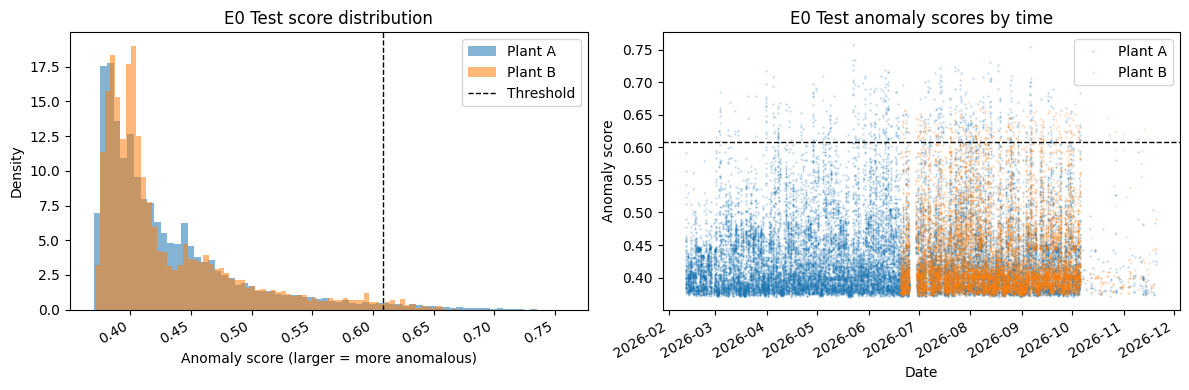

출력 경로: D:\KKW\_Repository\VSCode\github\CBNU.Master.1yr.intelIoT\termproj\llm_suggest\e0_output
저장 파일: 01_input_summary.csv
02_test_scored.csv
02_train_scored.csv
02_validation_scored.csv
03_plant_score_summary.csv
04_test_top30_per_plant.csv
05_test_monthly_alerts.csv
06_test_score_plots.png
e0_metadata.json
e0_unified_iforest.joblib


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for plant, g in scored['test'].groupby('source_plant'):
    axes[0].hist(g['anomaly_score'], bins=70, alpha=.55, density=True, label=f'Plant {plant}')
    axes[1].plot(g.sort_values('timestamp')['timestamp'],g.sort_values('timestamp')['anomaly_score'],'.',ms=1,alpha=.3,label=f'Plant {plant}')
for ax in axes:
    ax.axvline(threshold, ls='--', color='black', lw=1, label='Threshold') if ax is axes[0] else ax.axhline(threshold, ls='--', color='black', lw=1)
    ax.legend(loc='best')
axes[0].set(title='E0 Test score distribution',xlabel='Anomaly score (larger = more anomalous)',ylabel='Density')
axes[1].set(title='E0 Test anomaly scores by time',xlabel='Date',ylabel='Anomaly score')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT_DIR/'06_test_score_plots.png',dpi=140)
plt.show()
print('출력 경로:', OUT_DIR.resolve())
print('저장 파일:', '\n'.join(sorted(x.name for x in OUT_DIR.iterdir())))


## 7. 해석 및 다음 단계 (E1 준비)

1. `03_plant_score_summary.csv`에서 발전소 A/B의 Test 경보 비율 및 점수 분포를 확인합니다. 발전소 간 경보 비율이 크게 차이 나면 공통 모델의 편향 가능성을 검토합니다.
2. `04_test_top30_per_plant.csv`의 상위 이상 사례는 **점검 후보**일 뿐 실제 고장 레이블이 아닙니다.
3. `e0_unified_iforest.joblib`와 `e0_metadata.json`은 동일한 특징 입력 순서로 추론해야 합니다. OPC UA 연결 단계에서는 발전소별 시계열 상태를 독립 관리합니다.
4. 다음 **E1**은 같은 원본 Train/Validation/Test, 동일 E0 입력 4개 + 기온·습도·현지기압 특징을 사용합니다. 임계값은 실험마다 동일한 Validation 경보 비율 정책으로 보정하며, **두 모델의 경보 일치율·고정 이상 시나리오 탐지율**을 비교해야 합니다.
5. 실제 고장 레이블이 확보되기 전에는 정확도, Precision, Recall, F1, 실제 오탐률을 보고하지 않습니다.
